In [1]:
#!pip install xgboost joblib reportlab


In [2]:
from pathlib import Path
import json
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "data" / "raw" / "Crop_recommendation.csv").exists()),
    Path.cwd(),
)
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Crop_recommendation.csv"
RESULTS_DIR = PROJECT_ROOT / "crop_recommendation_results"
for folder in ["models", "reports", "visualizations"]:
    (RESULTS_DIR / folder).mkdir(parents=True, exist_ok=True)


## 1. Load dataset

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df.head()


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Clean and inspect the dataset


In [4]:
df.columns = [str(c).strip().lower() for c in df.columns]
required = ["n", "p", "k", "temperature", "humidity", "ph", "rainfall", "label"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Original shape:", df.shape)
print("Missing values:\n", df[required].isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Crop classes:", df["label"].nunique())
print(df["label"].value_counts().sort_index())


Original shape: (2200, 8)
Missing values:
 n              0
p              0
k              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Duplicate rows: 0
Crop classes: 22
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64


In [5]:
features = ["n", "p", "k", "temperature", "humidity", "ph", "rainfall"]
df = df.drop_duplicates().dropna(subset=required).copy()
for c in features:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=features + ["label"]).reset_index(drop=True)
df["label"] = df["label"].astype(str).str.strip().str.lower()
print("Cleaned shape:", df.shape)


Cleaned shape: (2200, 8)


## 3. Exploratory analysis


In [6]:
df[features].describe().T


,count,mean,std,min,25%,50%,75%,max
n,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
p,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
k,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


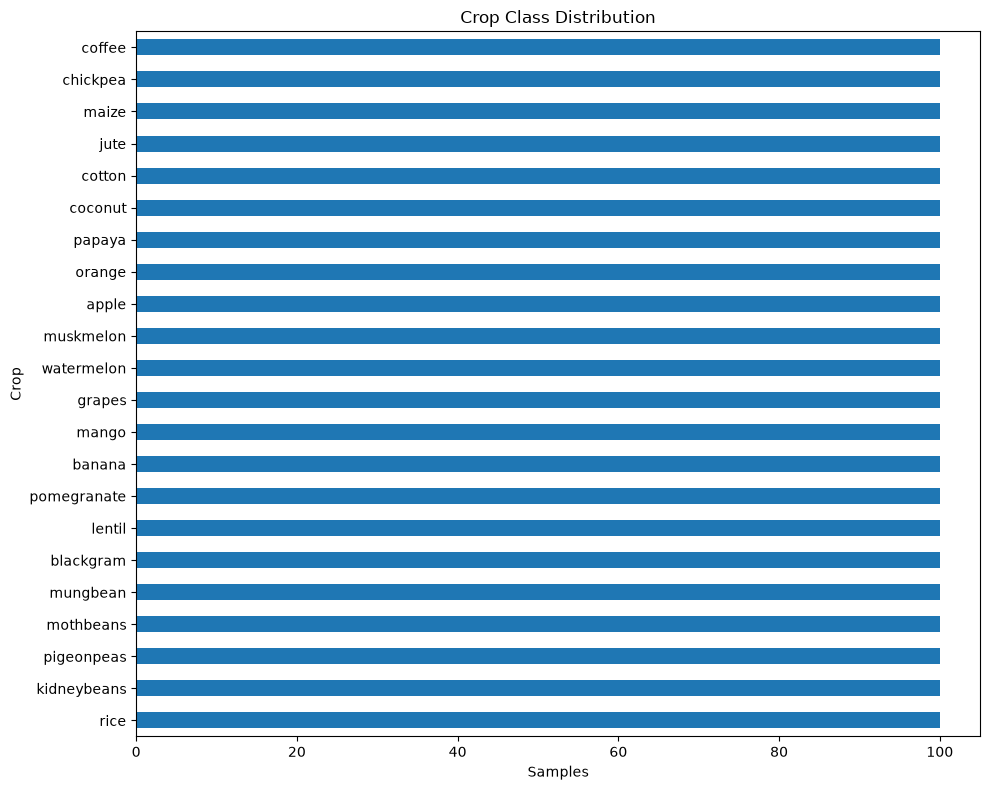

In [7]:
counts = df["label"].value_counts().sort_values()
plt.figure(figsize=(10, 8))
counts.plot(kind="barh")
plt.title("Crop Class Distribution")
plt.xlabel("Samples")
plt.ylabel("Crop")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "visualizations" / "00_class_distribution.png", dpi=300)
plt.show()


## 4. Prepare train and test data


In [8]:
X = df[features].copy()
encoder = LabelEncoder()
y = encoder.fit_transform(df["label"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Classes:", len(encoder.classes_))


Train: (1760, 7) Test: (440, 7)
Classes: 22


## 5. Train Random Forest and XGBoost


In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1,
)

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

print("Training Random Forest...")
rf.fit(X_train, y_train)
print("✓ Random Forest trained")
xgb.fit(X_train, y_train)
print("Training complete")


Training Random Forest...
✓ Random Forest trained


Training complete


## 6. Evaluate both models


In [10]:
def evaluate(name, model):
    pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="weighted", zero_division=0
    )
    result = {
        "Model": name,
        "Test Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
    }
    print(name, result)
    return result, pred

rf_result, rf_pred = evaluate("Random Forest", rf)
xgb_result, xgb_pred = evaluate("XGBoost", xgb)


Random Forest {'Model': 'Random Forest', 'Test Accuracy': 0.9954545454545455, 'Precision': 0.9956709956709956, 'Recall': 0.9954545454545455, 'F1-Score': 0.9954517027687759}
XGBoost {'Model': 'XGBoost', 'Test Accuracy': 0.9886363636363636, 'Precision': 0.9893742621015349, 'Recall': 0.9886363636363636, 'F1-Score': 0.9884930494686593}


## 7. Five-fold stratified cross-validation


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
import pandas as pd

# Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

# XGBoost model
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train both models
random_forest.fit(X_train, y_train)
xgboost_model.fit(X_train, y_train)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_cv = cross_val_score(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

xgb_cv = cross_val_score(
    xgboost_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Random Forest CV scores:", rf_cv)
print(f"Random Forest CV Accuracy: {rf_cv.mean():.4f} ± {rf_cv.std():.4f}")

print()

print("XGBoost CV scores:", xgb_cv)
print(f"XGBoost CV Accuracy: {xgb_cv.mean():.4f} ± {xgb_cv.std():.4f}")

# Add CV results to existing result dictionaries
rf_result["CV Accuracy Mean"] = rf_cv.mean()
rf_result["CV Accuracy Std"] = rf_cv.std()

xgb_result["CV Accuracy Mean"] = xgb_cv.mean()
xgb_result["CV Accuracy Std"] = xgb_cv.std()

comparison = pd.DataFrame([rf_result, xgb_result])

comparison = comparison[
    [
        "Model",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "CV Accuracy Mean",
        "CV Accuracy Std"
    ]
]

comparison.to_csv(
    RESULTS_DIR / "reports" / "model_comparison.csv",
    index=False
)

comparison

Random Forest CV scores: [1.         0.99715909 0.98863636 0.98863636 0.99715909]
Random Forest CV Accuracy: 0.9943 ± 0.0048

XGBoost CV scores: [0.99431818 0.99147727 0.99431818 0.99147727 0.99147727]
XGBoost CV Accuracy: 0.9926 ± 0.0014


,Model,Test Accuracy,Precision,Recall,F1-Score,CV Accuracy Mean,CV Accuracy Std
0,Random Forest,0.995455,0.995671,0.995455,0.995452,0.994318,0.004754
1,XGBoost,0.988636,0.989374,0.988636,0.988493,0.992614,0.001392


## 8. Compare models


In [12]:
comparison = pd.DataFrame([rf_result, xgb_result])
comparison.to_csv(RESULTS_DIR / "reports" / "model_comparison.csv", index=False)
comparison


,Model,Test Accuracy,Precision,Recall,F1-Score,CV Accuracy Mean,CV Accuracy Std
0,Random Forest,0.995455,0.995671,0.995455,0.995452,0.994318,0.004754
1,XGBoost,0.988636,0.989374,0.988636,0.988493,0.992614,0.001392


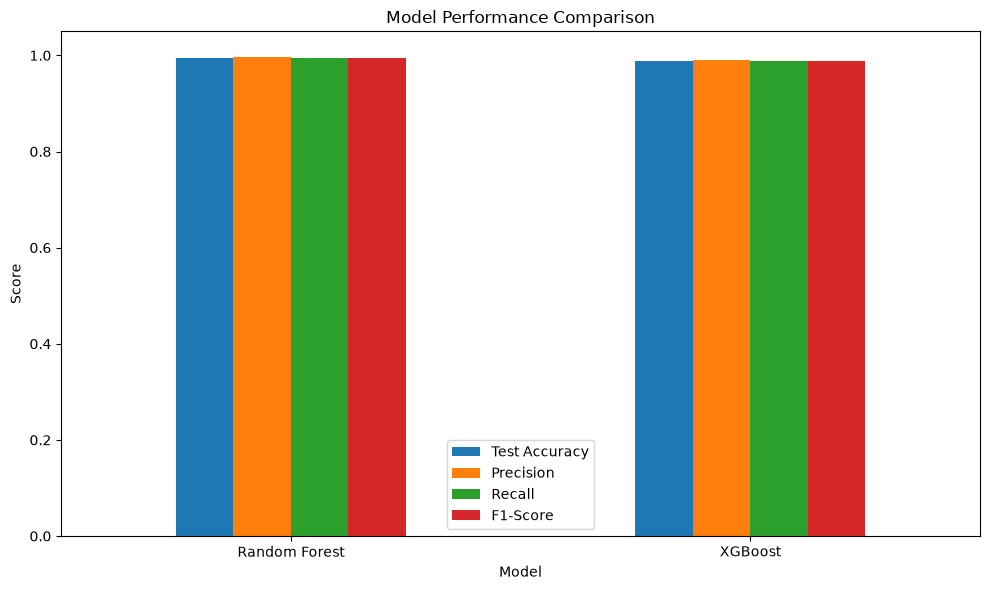

In [13]:
comparison.set_index("Model")[["Test Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "visualizations" / "03_metrics_comparison.png", dpi=300)
plt.show()


## 9. Confusion matrices


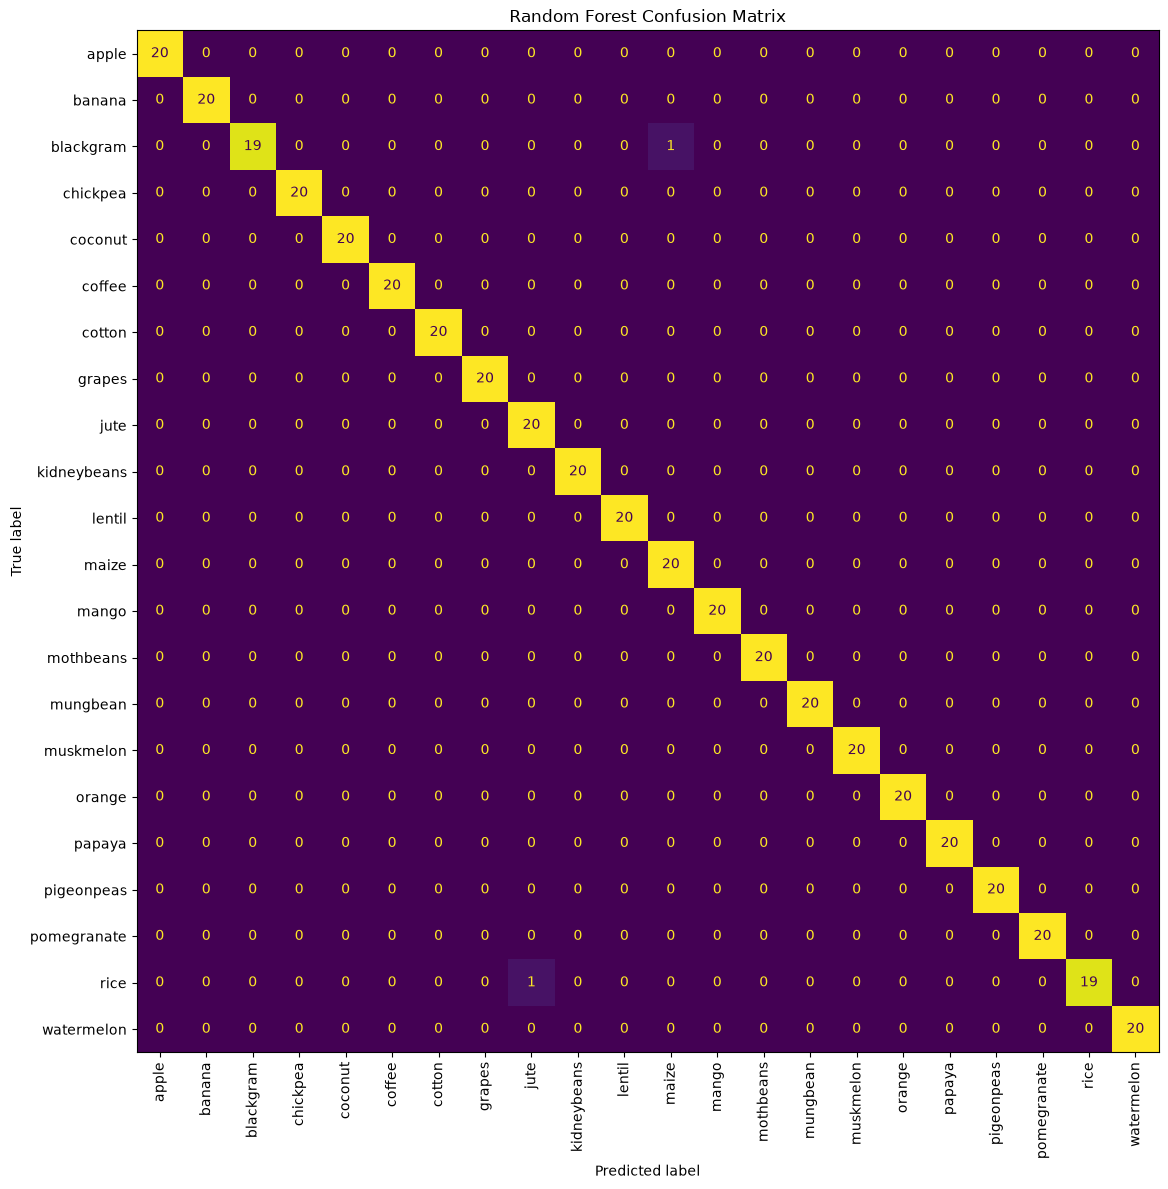

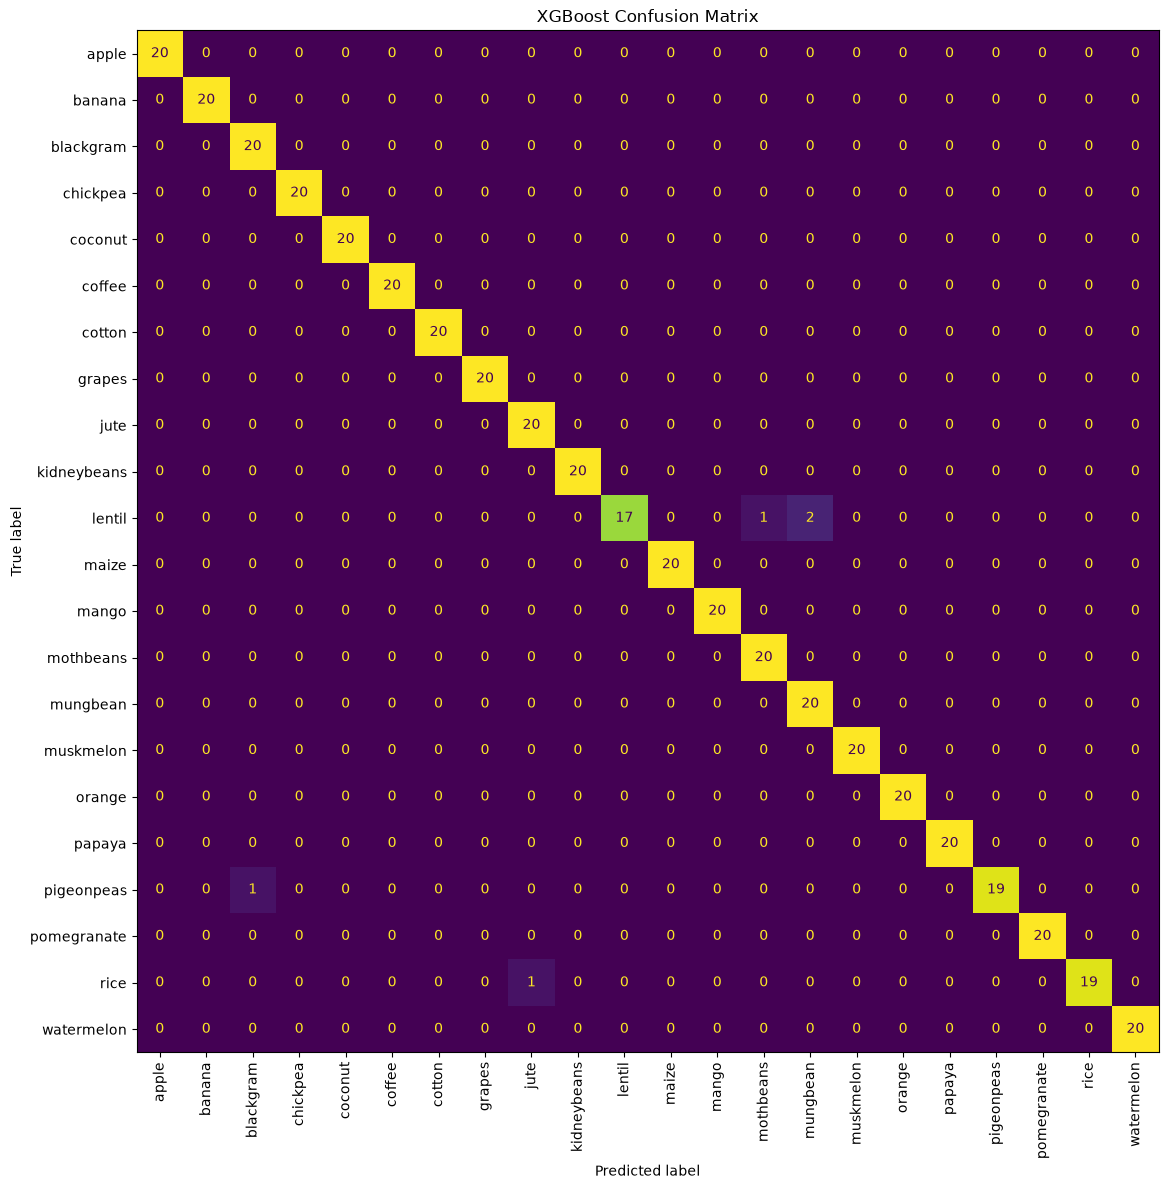

In [14]:
for name, pred in [("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:
    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=encoder.classes_, xticks_rotation=90,
        ax=ax, colorbar=False
    )
    ax.set_title(f"{name} Confusion Matrix")
    plt.tight_layout()
    file_name = name.lower().replace(" ", "_") + "_confusion_matrix.png"
    plt.savefig(RESULTS_DIR / "visualizations" / file_name, dpi=300)
    plt.show()


## 10. Random Forest feature importance


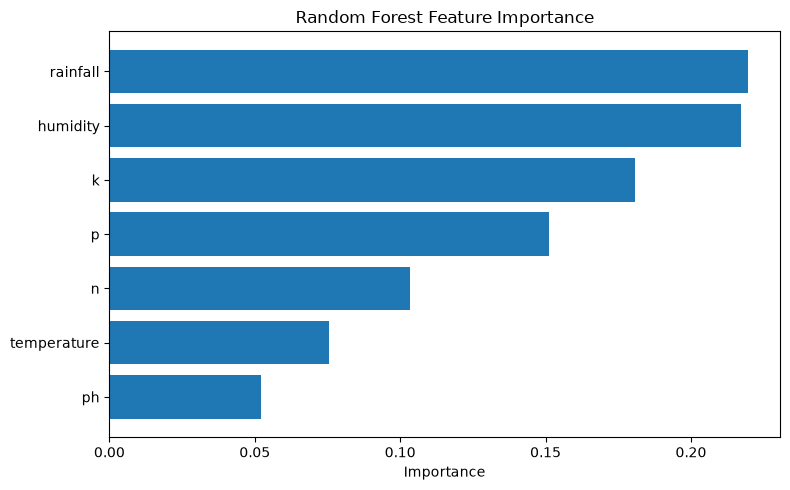

,Feature,Importance
6,rainfall,0.219641
4,humidity,0.217058
2,k,0.180813
1,p,0.151342
0,n,0.103356
3,temperature,0.075485
5,ph,0.052305


In [15]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "visualizations" / "02_feature_importance.png", dpi=300)
plt.show()

importance.sort_values("Importance", ascending=False)


## 11. Per-class report


In [16]:
report = classification_report(
    y_test, rf_pred, target_names=encoder.classes_, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).T
report_df.to_csv(RESULTS_DIR / "reports" / "random_forest_classification_report.csv")
report_df

,precision,recall,f1-score,support
apple,1.000000,1.000000,1.000000,20.000000
banana,1.000000,1.000000,1.000000,20.000000
blackgram,1.000000,0.950000,0.974359,20.000000
chickpea,1.000000,1.000000,1.000000,20.000000
coconut,1.000000,1.000000,1.000000,20.000000
coffee,1.000000,1.000000,1.000000,20.000000
cotton,1.000000,1.000000,1.000000,20.000000
grapes,1.000000,1.000000,1.000000,20.000000
jute,0.952381,1.000000,0.975610,20.000000
kidneybeans,1.000000,1.000000,1.000000,20.000000


## 12. Save the final model


In [17]:
best_name = comparison.sort_values(
    ["Test Accuracy", "CV Accuracy Mean"], ascending=False
).iloc[0]["Model"]
best_model = rf if best_name == "Random Forest" else xgb

joblib.dump(best_model, RESULTS_DIR / "models" / "best_crop_model.pkl")
joblib.dump(rf, RESULTS_DIR / "models" / "random_forest_model.pkl")
joblib.dump(xgb, RESULTS_DIR / "models" / "xgboost_model.pkl")
joblib.dump(encoder, RESULTS_DIR / "models" / "label_encoder.pkl")

metadata = {
    "best_model": best_name,
    "features": features,
    "classes": encoder.classes_.tolist(),
    "random_state": RANDOM_STATE,
}
with open(RESULTS_DIR / "reports" / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Best model:", best_name)
print("Saved to:", RESULTS_DIR.resolve())


Best model: Random Forest
Saved to: /Users/sreytouch/Desktop/Project Food Research WC/GrowAI_Code/crop_recommendation_results


## 13. Make a sample prediction


In [18]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    sample = pd.DataFrame([{
        "n": N, "p": P, "k": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall,
    }])
    pred_idx = best_model.predict(sample)[0]
    confidence = float(best_model.predict_proba(sample)[0].max())
    crop = encoder.inverse_transform([pred_idx])[0]
    return crop, confidence

crop, confidence = recommend_crop(90, 42, 43, 20.88, 82.0, 6.5, 202.94)
print(f"Recommended crop: {crop}")
print(f"Confidence: {confidence:.2%}")


Recommended crop: rice
Confidence: 93.50%


## 14. Explain feature importance

Feature importance measures how strongly the trained Random Forest used each input when making predictions. It shows model influence, not scientific causation.

In [19]:
importance_notes = {
    "rainfall": "Water availability and seasonal precipitation pattern",
    "humidity": "Atmospheric moisture and crop climate suitability",
    "k": "Potassium availability, water regulation, and stress tolerance",
    "p": "Phosphorus availability for roots and plant energy transfer",
    "n": "Nitrogen availability for vegetative growth",
    "temperature": "Thermal conditions affecting growth and development",
    "ph": "Soil acidity or alkalinity affecting nutrient availability",
}

importance_ranked = importance.sort_values("Importance", ascending=False).copy()
importance_ranked["Importance (%)"] = importance_ranked["Importance"] * 100
importance_ranked["Interpretation"] = importance_ranked["Feature"].map(importance_notes)
importance_ranked = importance_ranked[["Feature", "Importance (%)", "Interpretation"]]
importance_ranked.to_csv(
    RESULTS_DIR / "reports" / "feature_importance_explained.csv", index=False
)
display(importance_ranked.style.format({"Importance (%)": "{:.2f}"}))


,Feature,Importance (%),Interpretation
6,rainfall,21.96,Water availability and seasonal precipitation pattern
4,humidity,21.71,Atmospheric moisture and crop climate suitability
2,k,18.08,"Potassium availability, water regulation, and stress tolerance"
1,p,15.13,Phosphorus availability for roots and plant energy transfer
0,n,10.34,Nitrogen availability for vegetative growth
3,temperature,7.55,Thermal conditions affecting growth and development
5,ph,5.23,Soil acidity or alkalinity affecting nutrient availability


## 15. Analyze Random Forest misclassifications

The table below records every incorrect test prediction, including its input conditions and confidence. This makes the confusion matrix easier to explain.

In [20]:
rf_test_probabilities = rf.predict_proba(X_test)
test_predictions = X_test.reset_index().rename(columns={"index": "source_row"})
test_predictions["actual_crop"] = encoder.inverse_transform(y_test)
test_predictions["predicted_crop"] = encoder.inverse_transform(rf_pred)
test_predictions["confidence"] = rf_test_probabilities.max(axis=1)
test_predictions["correct"] = (
    test_predictions["actual_crop"] == test_predictions["predicted_crop"]
)
misclassified = test_predictions.loc[~test_predictions["correct"]].copy()

test_predictions.to_csv(RESULTS_DIR / "reports" / "random_forest_test_predictions.csv", index=False)
misclassified.to_csv(RESULTS_DIR / "reports" / "random_forest_misclassifications.csv", index=False)

print(f"Correct predictions: {test_predictions['correct'].sum()} / {len(test_predictions)}")
print(f"Misclassified samples: {len(misclassified)}")
if misclassified.empty:
    print("No test samples were misclassified.")
else:
    display(misclassified.style.format({"confidence": "{:.2%}"}))
    error_pairs = (
        misclassified.groupby(["actual_crop", "predicted_crop"])
        .size().rename("count").reset_index()
    )
    display(error_pairs)


Correct predictions: 438 / 440
Misclassified samples: 2


,source_row,n,p,k,temperature,humidity,ph,rainfall,actual_crop,predicted_crop,confidence,correct
178,789,60,59,22,31.868473,66.742175,7.191523,74.222386,blackgram,maize,56.00%,False
378,83,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute,67.00%,False


,actual_crop,predicted_crop,count
0,blackgram,maize,1
1,rice,jute,1


## 16. Test representative soil and weather scenarios

Each scenario uses the median observed conditions for a selected crop. This keeps the examples inside the dataset's observed range and provides a reproducible model check.

In [21]:
scenario_crops = ["rice", "maize", "chickpea", "watermelon", "apple"]
scenario_inputs = (
    df[df["label"].isin(scenario_crops)]
    .groupby("label", observed=True)[features]
    .median()
    .reindex(scenario_crops)
)
scenario_pred = rf.predict(scenario_inputs)
scenario_prob = rf.predict_proba(scenario_inputs).max(axis=1)
scenario_results = scenario_inputs.reset_index().rename(columns={"label": "expected_crop"})
scenario_results["recommended_crop"] = encoder.inverse_transform(scenario_pred)
scenario_results["confidence"] = scenario_prob
scenario_results["matches_expected"] = (
    scenario_results["expected_crop"] == scenario_results["recommended_crop"]
)
scenario_results.to_csv(RESULTS_DIR / "reports" / "sample_recommendations.csv", index=False)
display(scenario_results.style.format({"confidence": "{:.2%}"}))


,expected_crop,n,p,k,temperature,humidity,ph,rainfall,recommended_crop,confidence,matches_expected
0,rice,80.000000,47.000000,40.000000,23.734837,82.189357,6.363804,233.119859,rice,95.50%,True
1,maize,76.000000,48.500000,20.000000,22.844456,65.303845,6.259181,83.471553,maize,100.00%,True
2,chickpea,39.000000,68.000000,79.000000,18.878291,16.658634,7.356537,79.692282,chickpea,100.00%,True
3,watermelon,99.000000,17.500000,50.500000,25.603965,85.030605,6.469926,50.671903,watermelon,100.00%,True
4,apple,24.000000,136.500000,200.000000,22.628290,92.416541,5.885818,112.979230,apple,100.00%,True


## 17. Classify crops by typical growing context

These categories are practical product-design groupings, not strict agronomic rules. Suitability depends on climate, available space, local practices, and the GrowAI user's region.

In [22]:
crop_context = {
    "Home garden / small plot": [
        "apple", "banana", "grapes", "mango", "muskmelon", "orange",
        "papaya", "pomegranate", "watermelon",
    ],
    "Flexible: garden or field": [
        "blackgram", "chickpea", "kidneybeans", "lentil", "mothbeans",
        "mungbean", "pigeonpeas",
    ],
    "Primarily larger-scale / plantation": [
        "coconut", "coffee", "cotton", "jute", "maize", "rice",
    ],
}
context_rows = [
    {"crop": crop, "typical_context": context}
    for context, crops in crop_context.items()
    for crop in crops
]
crop_context_df = pd.DataFrame(context_rows).sort_values(["typical_context", "crop"])
uncategorized = sorted(set(encoder.classes_) - set(crop_context_df["crop"]))
if uncategorized:
    raise ValueError(f"Uncategorized crops: {uncategorized}")
crop_context_df.to_csv(RESULTS_DIR / "reports" / "crop_growing_context.csv", index=False)
display(crop_context_df.reset_index(drop=True))


,crop,typical_context
0,blackgram,Flexible: garden or field
1,chickpea,Flexible: garden or field
2,kidneybeans,Flexible: garden or field
3,lentil,Flexible: garden or field
4,mothbeans,Flexible: garden or field
5,mungbean,Flexible: garden or field
6,pigeonpeas,Flexible: garden or field
7,apple,Home garden / small plot
8,banana,Home garden / small plot
9,grapes,Home garden / small plot


## 18. Paper-ready methodology, results, and limitations

### Methodology
The crop recommendation dataset contains 2,200 observations distributed evenly across 22 crop classes. Seven soil and weather attributes were used: nitrogen (N), phosphorus (P), potassium (K), temperature, humidity, pH, and rainfall. After validating column names, removing duplicates, and excluding incomplete records, the data were divided using a stratified 80/20 train-test split with random state 42. Random Forest and XGBoost classifiers were compared using test accuracy, weighted precision, weighted recall, weighted F1-score, and five-fold stratified cross-validation.

### Results
Run the next cell to generate a paper-ready results paragraph directly from the current model outputs. This prevents the written metrics from becoming outdated when a library version or model setting changes.

### Limitations
- Results come from one balanced benchmark dataset and require validation with independent, location-specific field data.
- The dataset does not capture season, geographic location, soil type, sunlight, pests, irrigation access, cost, or user preferences.
- Random Forest feature importance describes model behavior and should not be interpreted as proof of causation.
- Predicted probabilities have not yet been calibrated, so confidence scores should be treated as model confidence rather than guaranteed suitability.
- GrowAI should present recommendations as decision support and include agronomic safety checks before real-world deployment.

In [23]:
feature_names_for_text = {
    "n": "nitrogen", "p": "phosphorus", "k": "potassium",
    "temperature": "temperature", "humidity": "humidity",
    "ph": "pH", "rainfall": "rainfall",
}
top_features_text = ", ".join(
    feature_names_for_text[name] for name in importance_ranked.head(5)["Feature"]
)
error_text = "; ".join(
    f"{row.actual_crop} predicted as {row.predicted_crop}"
    for row in misclassified.itertuples()
) or "none"
results_text = (
    f"Random Forest achieved {rf_result['Test Accuracy']:.2%} test accuracy, "
    f"{rf_result['Precision']:.2%} weighted precision, {rf_result['Recall']:.2%} "
    f"weighted recall, and a {rf_result['F1-Score']:.2%} weighted F1-score. "
    f"Its mean cross-validation accuracy was {rf_result['CV Accuracy Mean']:.2%} "
    f"with a standard deviation of {rf_result['CV Accuracy Std']:.2%}. "
    f"XGBoost achieved {xgb_result['Test Accuracy']:.2%} test accuracy and "
    f"{xgb_result['CV Accuracy Mean']:.2%} mean cross-validation accuracy. "
    f"{best_name} was selected as the final model. Random Forest correctly classified "
    f"{int((rf_pred == y_test).sum())} of {len(y_test)} test samples. "
    f"The misclassification pairs were: {error_text}. The five most influential "
    f"features were {top_features_text}."
)
(RESULTS_DIR / "reports" / "paper_results_summary.txt").write_text(results_text)
print(results_text)


Random Forest achieved 99.55% test accuracy, 99.57% weighted precision, 99.55% weighted recall, and a 99.55% weighted F1-score. Its mean cross-validation accuracy was 99.43% with a standard deviation of 0.48%. XGBoost achieved 98.86% test accuracy and 99.26% mean cross-validation accuracy. Random Forest was selected as the final model. Random Forest correctly classified 438 of 440 test samples. The misclassification pairs were: blackgram predicted as maize; rice predicted as jute. The five most influential features were rainfall, humidity, potassium, phosphorus, nitrogen.


## 19. Connect crop recommendation to GrowAI plant care

Proposed application flow:

1. The user enters soil nutrients and local weather conditions.
2. The Random Forest returns a recommended crop and confidence score.
3. GrowAI combines the crop with live weather, location, and growth-stage information.
4. The watering component estimates timing and water demand instead of using a fixed schedule.
5. The plant-care component provides crop-specific planting, nutrition, disease-prevention, and maintenance guidance.
6. The application records user feedback and observed outcomes for future model validation.

A low-confidence prediction should trigger alternative crop suggestions or a request for additional information rather than a single definitive recommendation.

In [24]:
friday_summary = {
    "best_model": best_name,
    "test_samples": int(len(y_test)),
    "correct_predictions": int((rf_pred == y_test).sum()),
    "misclassified_samples": int((rf_pred != y_test).sum()),
    "random_forest_test_accuracy": float(rf_result["Test Accuracy"]),
    "random_forest_cv_mean": float(rf_result["CV Accuracy Mean"]),
    "xgboost_test_accuracy": float(xgb_result["Test Accuracy"]),
    "xgboost_cv_mean": float(xgb_result["CV Accuracy Mean"]),
    "top_features": importance_ranked.head(5)["Feature"].tolist(),
}
with open(RESULTS_DIR / "reports" / "friday_meeting_summary.json", "w") as f:
    json.dump(friday_summary, f, indent=2)
print(json.dumps(friday_summary, indent=2))


{
  "best_model": "Random Forest",
  "test_samples": 440,
  "correct_predictions": 438,
  "misclassified_samples": 2,
  "random_forest_test_accuracy": 0.9954545454545455,
  "random_forest_cv_mean": 0.9943181818181819,
  "xgboost_test_accuracy": 0.9886363636363636,
  "xgboost_cv_mean": 0.9926136363636363,
  "top_features": [
    "rainfall",
    "humidity",
    "k",
    "p",
    "n"
  ]
}


## 20. Export CSV reports to PDF

This creates a matching PDF beside every CSV file in the reports folder. Wide tables automatically use a larger landscape page.

In [ ]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

try:
    from src.utils.export_model_report_pdfs import export_all_report_pdfs
except ImportError as exc:
    raise ImportError(
        "PDF export requires reportlab. Run: pip install reportlab"
    ) from exc

pdf_reports = export_all_report_pdfs(RESULTS_DIR / "reports")
print(f"Created {len(pdf_reports)} PDF reports:")
for pdf_path in pdf_reports:
    print(f"- {pdf_path.name}")
